# E-Commerce Delivery and Shipping Performance Analysis Using Python

## Problem Statement

E-commerce companies handle large volumes of orders across different locations, shipping methods, carriers, and product categories. Delivery delays, shipping costs, returns, and customer satisfaction can significantly affect overall business performance.

This project aims to analyze e-commerce delivery and shipping data using Python to identify delivery patterns, evaluate shipping performance, understand the factors associated with delays and returns, and derive meaningful insights that can support better operational and customer-service decisions.

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Loading and Initial Overview

In [2]:
df = pd.read_csv("E-commerce_Delivery_Shipping_Data_2026.csv")

In [3]:
df.head()

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.1,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.9,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.5,Delivered
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,...,Large,Debit Card,Normal,Snow,3,No,NaN,1,12.6,In Transit
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,...,Small,Credit Card,Normal,Storm,2,No,NaN,1,24.9,Delivered


### Dataset Structure

The dataset structure is examined to understand the number of records, features, column names, and data types before performing data cleaning and exploratory analysis.

In [4]:
df.shape

(50000, 30)

In [5]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_segment',
       'customer_city', 'customer_country', 'warehouse_id', 'warehouse_city',
       'product_category', 'product_weight_kg', 'order_value_usd',
       'shipping_method', 'carrier', 'distance_km', 'promised_delivery_days',
       'actual_delivery_days', 'delivery_status', 'late_delivery',
       'delivery_delay_days', 'shipping_cost_usd', 'package_size',
       'payment_method', 'order_priority', 'weather_condition',
       'customer_rating', 'return_requested', 'return_reason',
       'delivery_attempts', 'warehouse_processing_hours', 'tracking_status'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    50000 non-null  object 
 1   order_date                  50000 non-null  object 
 2   customer_id                 50000 non-null  object 
 3   customer_segment            50000 non-null  object 
 4   customer_city               50000 non-null  object 
 5   customer_country            50000 non-null  object 
 6   warehouse_id                50000 non-null  object 
 7   warehouse_city              50000 non-null  object 
 8   product_category            50000 non-null  object 
 9   product_weight_kg           50000 non-null  float64
 10  order_value_usd             50000 non-null  float64
 11  shipping_method             50000 non-null  object 
 12  carrier                     50000 non-null  object 
 13  distance_km                 500

### Statistical Summary

Descriptive statistics are used to understand the distribution, central tendency, and range of the numerical variables in the dataset.

In [7]:
df.describe()

,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating,delivery_attempts,warehouse_processing_hours
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2.255028,177.917107,2496.778802,7.197700,8.345940,1.281080,120.515538,3.371840,1.169860,14.412430
std,3.694952,291.600047,1774.633152,3.680229,4.644353,1.679527,108.680030,0.998777,0.390756,9.924904
min,0.100000,10.000000,40.000000,0.000000,0.000000,0.000000,4.050000,1.000000,1.000000,1.000000
25%,0.320000,28.720000,1086.775000,4.000000,5.000000,0.000000,40.640000,3.000000,1.000000,6.600000
50%,0.930000,76.840000,2182.800000,6.000000,8.000000,1.000000,82.970000,3.000000,1.000000,11.900000
75%,2.610000,173.162500,3592.475000,11.000000,12.000000,2.000000,167.422500,4.000000,1.000000,20.700000
max,52.190000,3530.730000,9553.600000,15.000000,27.000000,13.000000,500.000000,5.000000,3.000000,48.000000


## 3. Data Pre-processing

The dataset is checked for missing values, duplicate records, incorrect data types, and other data-quality issues before exploratory data analysis.

In [8]:
df.isnull().sum()

order_id                          0
order_date                        0
customer_id                       0
customer_segment                  0
customer_city                     0
customer_country                  0
warehouse_id                      0
warehouse_city                    0
product_category                  0
product_weight_kg                 0
order_value_usd                   0
shipping_method                   0
carrier                           0
distance_km                       0
promised_delivery_days            0
actual_delivery_days              0
delivery_status                   0
late_delivery                     0
delivery_delay_days               0
shipping_cost_usd                 0
package_size                      0
payment_method                    0
order_priority                    0
weather_condition                 0
customer_rating                   0
return_requested                  0
return_reason                 41375
delivery_attempts           

In [9]:
pd.crosstab(
    df['return_requested'],
    df['return_reason'].isnull()
)

return_reason,False,True
return_requested,,
No,0,41375
Yes,8625,0


### Handling Missing Values

The `return_reason` column contains 41,375 missing values. Cross-tabulation confirmed that all missing values correspond to orders where no return was requested. Therefore, these values are contextual rather than data-quality issues and are replaced with `Not Applicable`.

In [10]:
df['return_reason'] = df['return_reason'].fillna('Not Applicable')

In [11]:
df.isnull().sum().sum()

np.int64(0)

### Checking Duplicate Records

Duplicate records are checked to ensure that the same observation is not counted more than once during the analysis.

In [12]:
df.duplicated().sum()

np.int64(0)

### Correcting Data Types

The `order_date` column is stored as an object (text). It is converted to datetime format to enable accurate date-based analysis and feature engineering.

In [13]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [14]:
df['order_date'].dtype

dtype('<M8[ns]')

### Feature Engineering

New features are created from the existing data to support deeper exploratory analysis. The order month is extracted from `order_date` to analyze monthly order and delivery patterns.

In [15]:
df['order_month'] = df['order_date'].dt.month_name()

In [16]:
df[['order_date', 'order_month']].head()

,order_date,order_month
0,2026-11-15,November
1,2026-04-08,April
2,2026-01-05,January
3,2026-05-29,May
4,2026-02-22,February


In [17]:
df['order_day'] = df['order_date'].dt.day_name()

In [18]:
df[['order_date', 'order_month', 'order_day']].head()

,order_date,order_month,order_day
0,2026-11-15,November,Sunday
1,2026-04-08,April,Wednesday
2,2026-01-05,January,Monday
3,2026-05-29,May,Friday
4,2026-02-22,February,Sunday


### Final Data Quality Check

After preprocessing, the dataset is verified to confirm that there are no remaining missing values or duplicate records and that the newly engineered features have been successfully added.

In [19]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Order Date Type:", df['order_date'].dtype)

Dataset Shape: (50000, 32)
Missing Values: 0
Duplicate Rows: 0
Order Date Type: datetime64[ns]


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to identify patterns, distributions, relationships, and trends in the e-commerce delivery data. The analysis includes univariate, bivariate, and multivariate analysis supported by appropriate visualizations.

### 4.1 Univariate Analysis

Univariate analysis is used to examine the distribution and frequency of individual variables.

In [20]:
df['delivery_status'].value_counts()

delivery_status
Delivered          44184
In Transit          4007
Delayed             1806
Failed Delivery        3
Name: count, dtype: int64

In [21]:
df['shipping_method'].value_counts()

shipping_method
Standard         17027
International    15839
Express           9696
Economy           5577
Same Day          1861
Name: count, dtype: int64

In [22]:
df['carrier'].value_counts()

carrier
BlueRoute              6435
ParcelPro              6374
SpeedyCargo            6257
SwiftShip              6233
GlobalExpress          6231
EagleCourier           6213
PrimeDelivery          6185
FastTrack Logistics    6072
Name: count, dtype: int64

### 4.2 GroupBy Analysis

GroupBy analysis is used to compare delivery performance across different shipping methods. The average promised delivery time, actual delivery time, delivery delay, shipping cost, and customer rating are calculated for each shipping method.

In [23]:
shipping_summary = df.groupby('shipping_method').agg({
    'promised_delivery_days': 'mean',
    'actual_delivery_days': 'mean',
    'delivery_delay_days': 'mean',
    'shipping_cost_usd': 'mean',
    'customer_rating': 'mean'
}).round(2)

shipping_summary

,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating
shipping_method,,,,,
Economy,9.27,10.56,1.50,48.91,3.28
Express,3.02,3.61,0.62,107.58,3.57
International,11.64,13.51,2.08,204.40,3.20
Same Day,1.13,1.42,0.29,136.58,3.84
Standard,5.42,6.28,0.96,71.55,3.40


### 4.3 Pivot Table Analysis

A pivot table is used to compare the average delivery delay across shipping methods and weather conditions. This helps identify whether delivery performance varies under different operating conditions.

In [24]:
delay_pivot = pd.pivot_table(
    df,
    values='delivery_delay_days',
    index='shipping_method',
    columns='weather_condition',
    aggfunc='mean'
).round(2)

delay_pivot

weather_condition,Clear,Cloudy,Extreme Heat,Rain,Snow,Storm
shipping_method,,,,,,
Economy,0.57,0.90,1.15,1.60,3.88,3.40
Express,0.29,0.40,0.54,0.66,1.40,1.31
International,0.88,1.26,1.68,2.25,5.19,4.57
Same Day,0.19,0.21,0.20,0.31,0.58,0.51
Standard,0.43,0.60,0.82,1.03,2.34,2.08


### 4.4 Correlation Analysis

Correlation analysis is used to examine the strength and direction of relationships between numerical variables in the dataset. This helps identify variables that may be associated with delivery time, delays, shipping cost, and customer ratings.

In [25]:
numeric_columns = [
    'product_weight_kg',
    'order_value_usd',
    'distance_km',
    'promised_delivery_days',
    'actual_delivery_days',
    'delivery_delay_days',
    'shipping_cost_usd',
    'customer_rating',
    'delivery_attempts',
    'warehouse_processing_hours'
]

correlation_matrix = df[numeric_columns].corr().round(2)

correlation_matrix

,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating,delivery_attempts,warehouse_processing_hours
product_weight_kg,1.00,0.15,0.00,0.00,0.00,0.00,0.24,-0.00,-0.01,-0.00
order_value_usd,0.15,1.00,0.00,0.00,0.01,0.01,0.05,-0.01,0.00,0.00
distance_km,0.00,0.00,1.00,0.49,0.52,0.36,0.82,-0.22,0.01,0.00
promised_delivery_days,0.00,0.00,0.49,1.00,0.93,0.42,0.51,-0.20,-0.00,0.01
actual_delivery_days,0.00,0.01,0.52,0.93,1.00,0.71,0.53,-0.36,0.02,0.11
delivery_delay_days,0.00,0.01,0.36,0.42,0.71,1.00,0.34,-0.51,0.05,0.24
shipping_cost_usd,0.24,0.05,0.82,0.51,0.53,0.34,1.00,-0.18,0.00,-0.00
customer_rating,-0.00,-0.01,-0.22,-0.20,-0.36,-0.51,-0.18,1.00,-0.04,-0.19
delivery_attempts,-0.01,0.00,0.01,-0.00,0.02,0.05,0.00,-0.04,1.00,0.02
warehouse_processing_hours,-0.00,0.00,0.00,0.01,0.11,0.24,-0.00,-0.19,0.02,1.00


**Correlation Observations:**

- Distance and shipping cost show a strong positive correlation (0.82), indicating that longer delivery distances are generally associated with higher shipping costs.
- Promised and actual delivery days have a very strong positive correlation (0.93).
- Actual delivery days and delivery delay show a strong positive correlation (0.71).
- Delivery delay and customer rating show a moderate negative correlation (-0.51), indicating that higher delays are associated with lower customer ratings.
- Correlation represents association and does not necessarily imply causation.

### 4.5 Data Visualizations

#### Visualization 1: Delivery Status Distribution

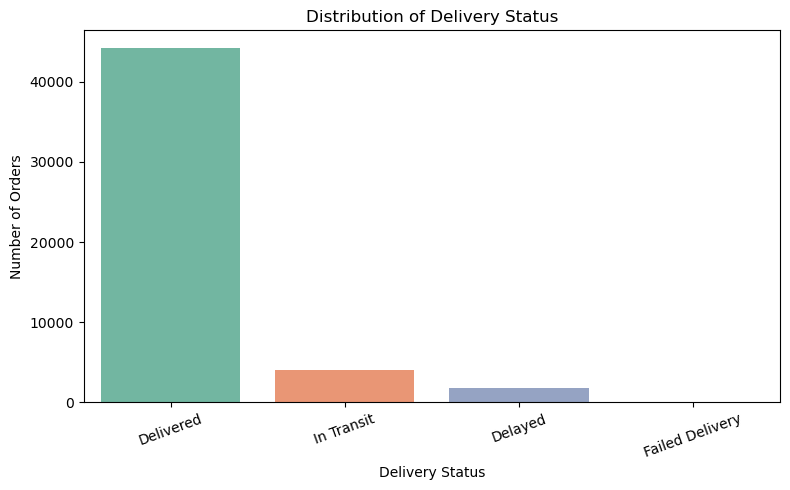

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='delivery_status',
    order=df['delivery_status'].value_counts().index,
    hue='delivery_status',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretation:**  
The majority of orders are in the Delivered category (44,184), while 4,007 orders are In Transit and 1,806 are Delayed. Only 3 orders are recorded as Failed Delivery, indicating that failed deliveries are very rare in the dataset.

#### Visualization 2: Shipping Method Distribution

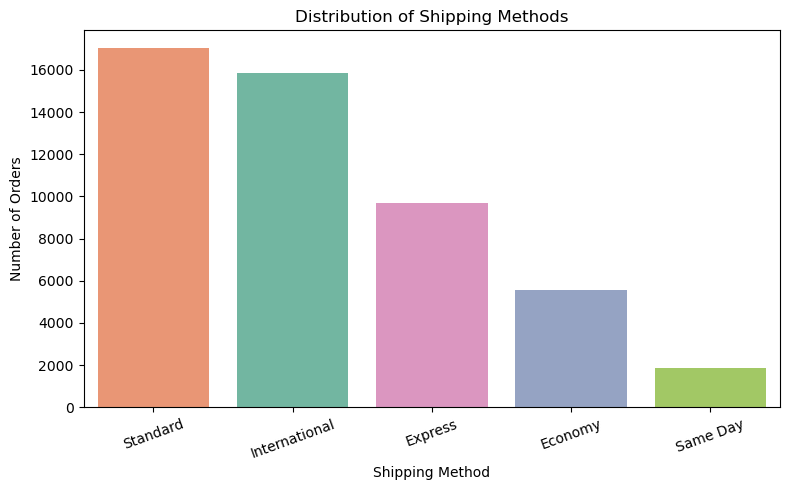

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='shipping_method',
    order=df['shipping_method'].value_counts().index,
    hue='shipping_method',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Shipping Methods')
plt.xlabel('Shipping Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretation:**  
Standard is the most frequently used shipping method with 17,027 orders, followed by International with 15,839 orders and Express with 9,696 orders. Economy accounts for 5,577 orders, while Same Day is the least frequently used method with 1,861 orders.

#### Visualization 3: Average Delivery Delay by Shipping Method

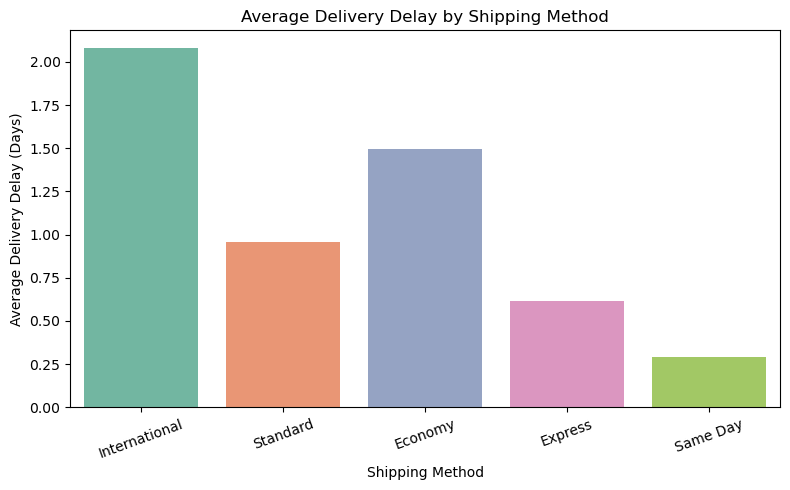

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='shipping_method',
    y='delivery_delay_days',
    hue='shipping_method',
    palette='Set2',
    legend=False,
    errorbar=None
)

plt.title('Average Delivery Delay by Shipping Method')
plt.xlabel('Shipping Method')
plt.ylabel('Average Delivery Delay (Days)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretation:**  
International shipping has the highest average delivery delay at 2.08 days, followed by Economy at 1.50 days. Standard and Express show lower average delays of 0.96 and 0.62 days respectively, while Same Day has the lowest average delay at 0.29 days.

#### Visualization 4: Average Shipping Cost by Shipping Method

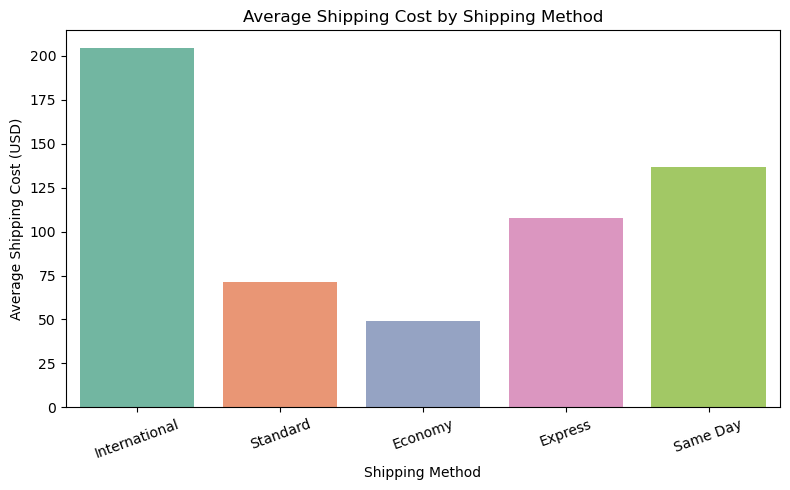

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='shipping_method',
    y='shipping_cost_usd',
    hue='shipping_method',
    palette='Set2',
    legend=False,
    errorbar=None
)

plt.title('Average Shipping Cost by Shipping Method')
plt.xlabel('Shipping Method')
plt.ylabel('Average Shipping Cost (USD)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretation:**  
International shipping has the highest average shipping cost at $204.40, followed by Same Day at $136.58 and Express at $107.58. Standard has an average cost of $71.55, while Economy has the lowest average shipping cost at $48.91.

#### Visualization 5: Average Delivery Delay by Weather Condition

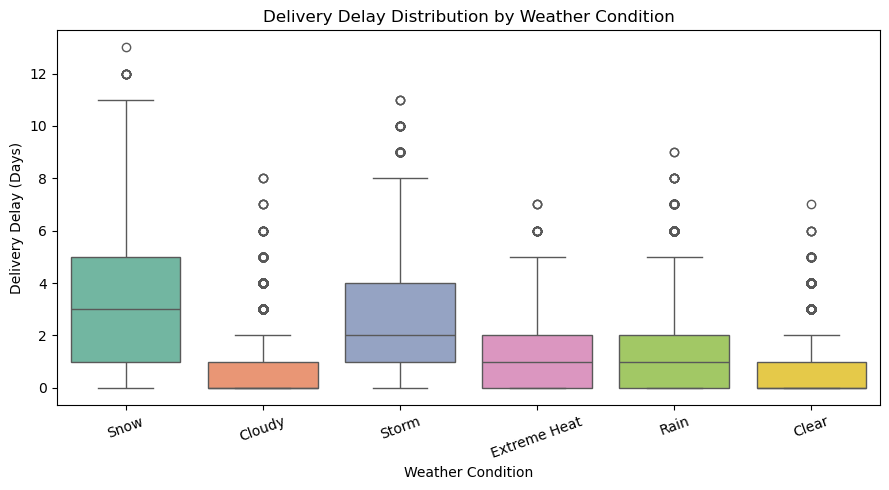

In [30]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='weather_condition',
    y='delivery_delay_days',
    hue='weather_condition',
    palette='Set2',
    legend=False
)

plt.title('Delivery Delay Distribution by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Delivery Delay (Days)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretation:**  
Delivery delays vary noticeably across weather conditions. Snow shows the highest median delay and the greatest spread, followed by Storm, while Clear and Cloudy conditions generally show lower delays. Several high-delay outliers are also observed across the weather categories.

#### Visualization 6: Distance vs Shipping Cost

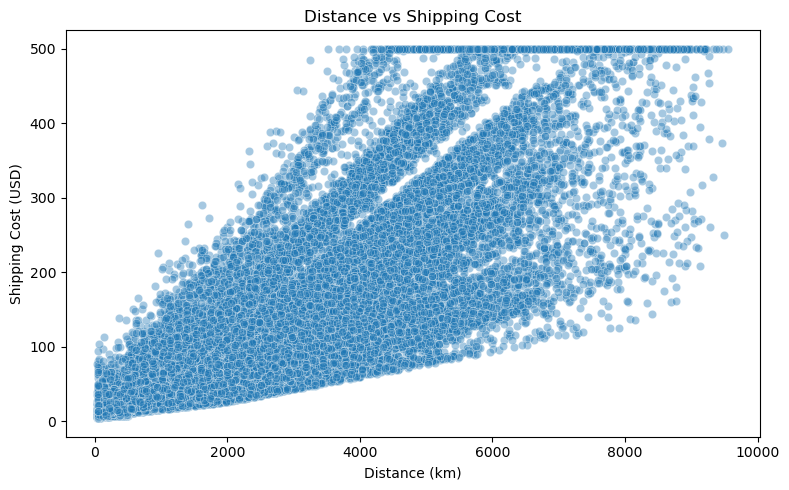

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='distance_km',
    y='shipping_cost_usd',
    alpha=0.4
)

plt.title('Distance vs Shipping Cost')
plt.xlabel('Distance (km)')
plt.ylabel('Shipping Cost (USD)')
plt.tight_layout()
plt.show()

**Interpretation:**  
The scatter plot shows a strong positive relationship between delivery distance and shipping cost. Longer delivery distances are generally associated with higher shipping costs, which is consistent with the correlation value of 0.82.

#### Visualization 7: Delivery Delay vs Customer Rating

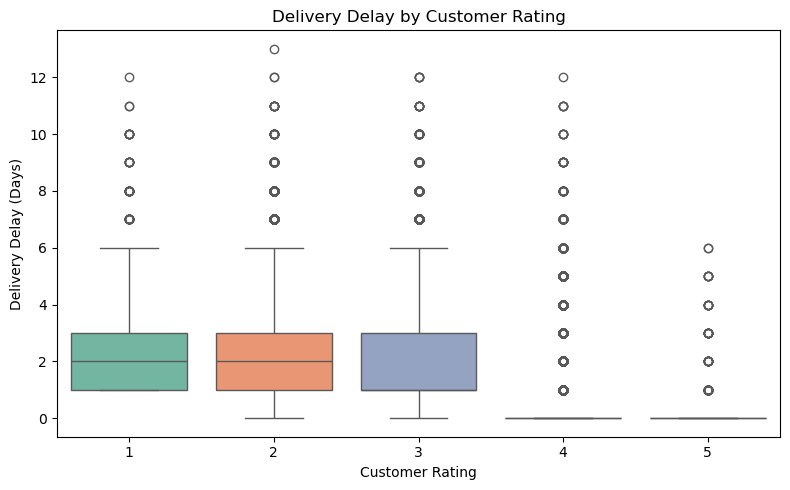

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='customer_rating',
    y='delivery_delay_days',
    hue='customer_rating',
    palette='Set2',
    legend=False
)

plt.title('Delivery Delay by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Delivery Delay (Days)')
plt.tight_layout()
plt.show()

**Interpretation:**  
Lower customer ratings are associated with higher delivery delays. Ratings 1–3 show higher typical delays, while ratings 4 and 5 generally have little or no delay. This pattern is consistent with the negative correlation (-0.51) between delivery delay and customer rating.

#### Visualization 8: Monthly Order Trend

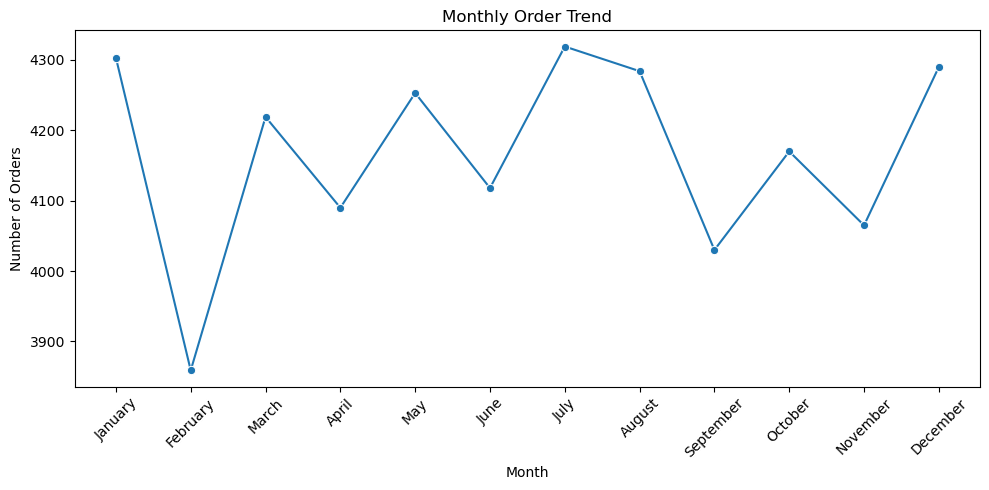

In [36]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_orders = df['order_month'].value_counts().reindex(month_order)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_orders.index,
    y=monthly_orders.values,
    marker='o'
)

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:**  
Monthly order volume remains relatively stable throughout the year with moderate fluctuations. July records the highest number of orders, while February records the lowest. No strong overall increasing or decreasing trend is observed.

#### Visualization 9: Correlation Heatmap

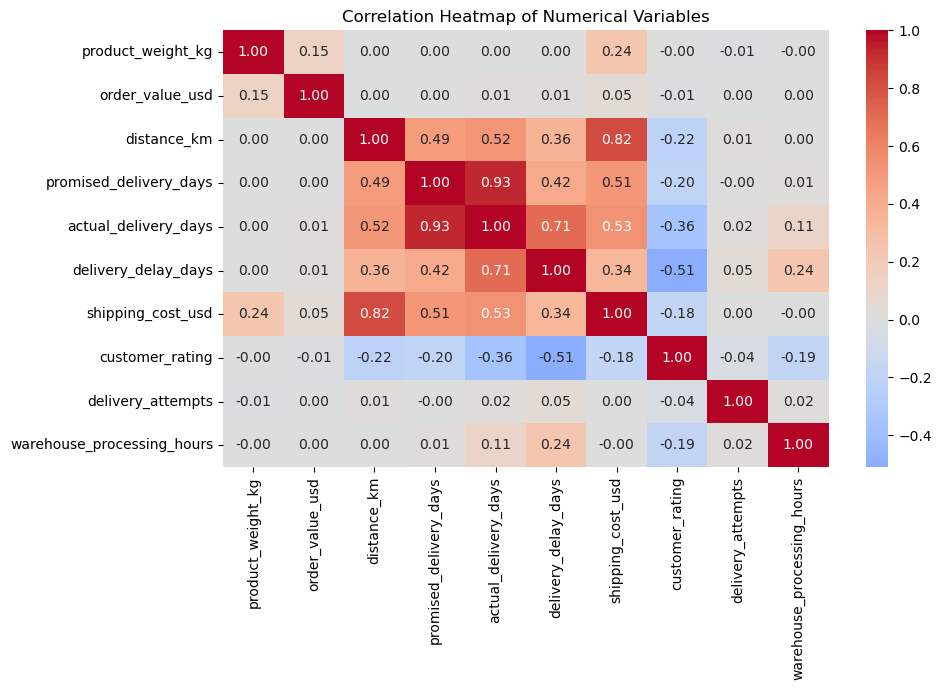

In [37]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

**Interpretation:**  
The heatmap shows strong positive relationships between promised and actual delivery days (0.93) and between distance and shipping cost (0.82). Actual delivery days and delivery delay are also strongly positively related (0.71). Delivery delay has a moderate negative relationship with customer rating (-0.51), indicating that higher delays are associated with lower customer ratings.

#### Visualization 10: Return Request Distribution

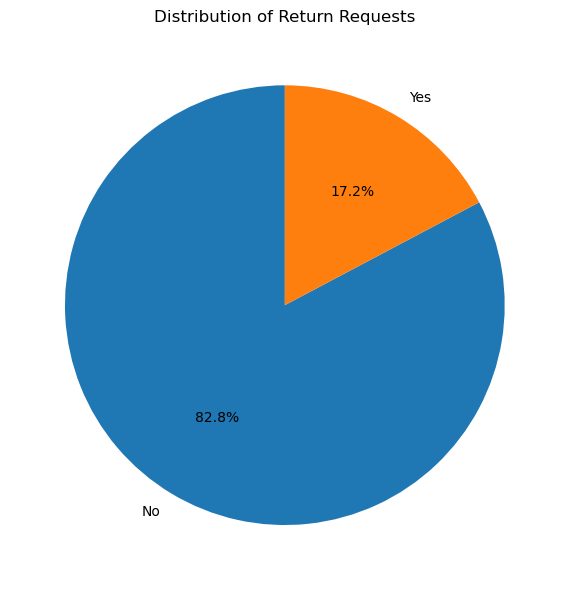

In [38]:
return_counts = df['return_requested'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    return_counts.values,
    labels=return_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Return Requests')
plt.tight_layout()
plt.show()

**Interpretation:**  
The majority of orders (82.8%) did not have a return request, while 17.2% of orders were returned. This shows that return requests represent a relatively smaller proportion of the total orders.

#### Visualization 11: Return Reasons Distribution

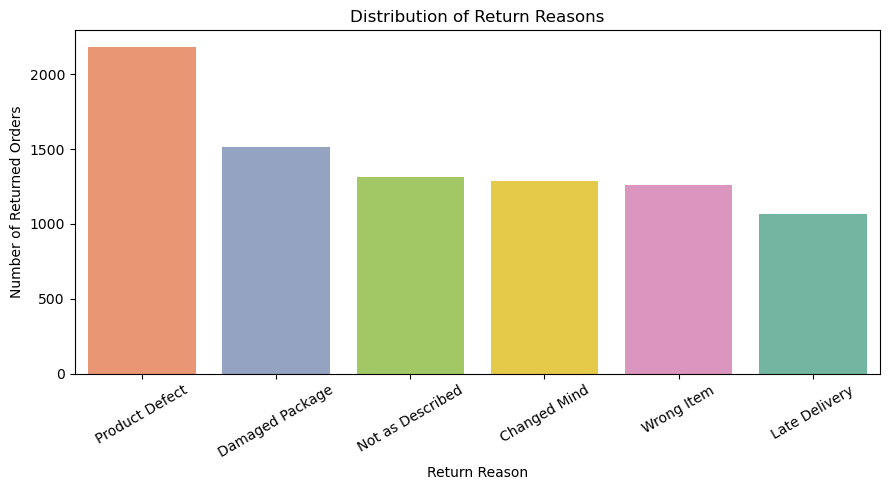

In [39]:
returned_orders = df[df['return_requested'] == 'Yes']

plt.figure(figsize=(9, 5))

sns.countplot(
    data=returned_orders,
    x='return_reason',
    order=returned_orders['return_reason'].value_counts().index,
    hue='return_reason',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Return Reasons')
plt.xlabel('Return Reason')
plt.ylabel('Number of Returned Orders')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Interpretation:**  
Product Defect is the most common reason for product returns, followed by Damaged Package. Not as Described, Changed Mind, and Wrong Item also contribute to returns, while Late Delivery is the least common return reason in the dataset.

#### Visualization 12: Average Delivery Delay by Carrier

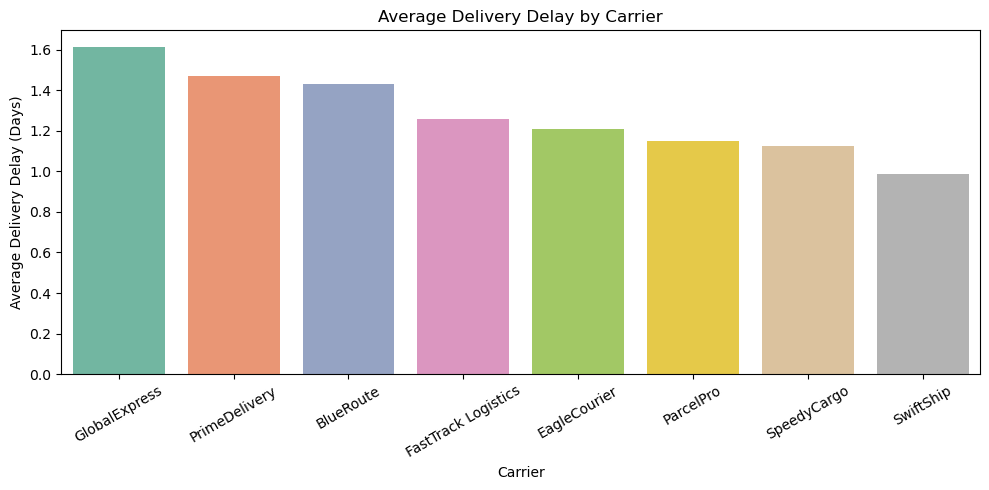

In [40]:
carrier_delay = (
    df.groupby('carrier')['delivery_delay_days']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=carrier_delay.index,
    y=carrier_delay.values,
    hue=carrier_delay.index,
    palette='Set2',
    legend=False
)

plt.title('Average Delivery Delay by Carrier')
plt.xlabel('Carrier')
plt.ylabel('Average Delivery Delay (Days)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Interpretation:**  
Average delivery delay varies across carriers. GlobalExpress shows the highest average delay at approximately 1.61 days, followed by PrimeDelivery and BlueRoute. SwiftShip records the lowest average delay at approximately 0.99 days, indicating comparatively lower delivery delays among the carriers analyzed.

### Visualization 13: On-Time Delivery Rate by Shipping Method

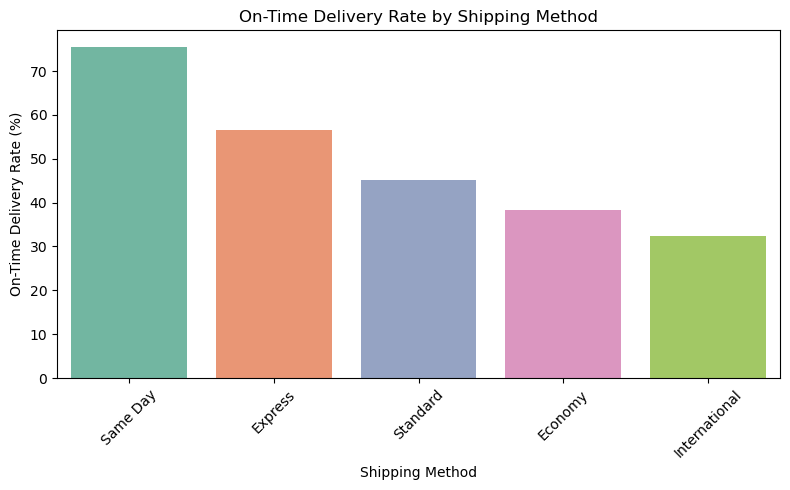

In [41]:
# Create on-time delivery indicator
df['on_time_delivery'] = df['delivery_delay_days'] <= 0

# Calculate on-time delivery percentage by shipping method
on_time_rate = (
    df.groupby('shipping_method')['on_time_delivery']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=on_time_rate.index,
    y=on_time_rate.values,
    hue=on_time_rate.index,
    palette='Set2',
    legend=False
)

plt.title('On-Time Delivery Rate by Shipping Method')
plt.xlabel('Shipping Method')
plt.ylabel('On-Time Delivery Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:**  
This visualization compares the on-time delivery performance of different shipping methods. A higher percentage indicates better delivery reliability. The analysis helps identify which shipping methods are more effective in meeting promised delivery times.

### Visualization 14: Average Delivery Delay by Distance Category

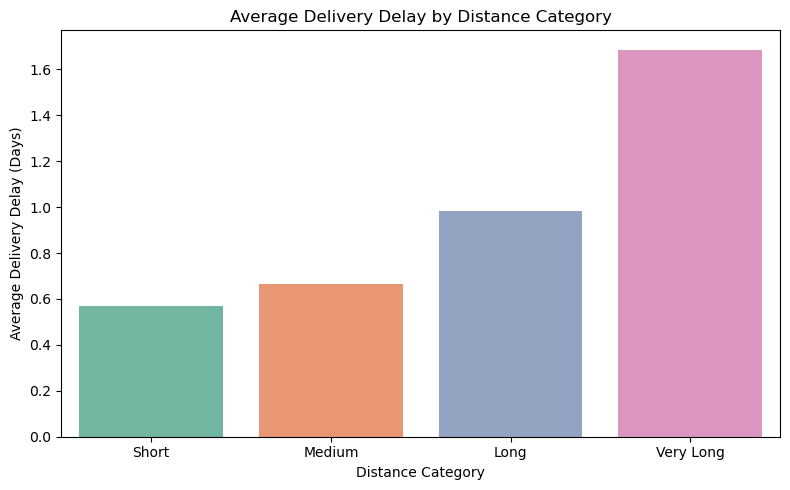

In [42]:
# Create distance categories
df['distance_category'] = pd.cut(
    df['distance_km'],
    bins=[0, 500, 1000, 2000, float('inf')],
    labels=['Short', 'Medium', 'Long', 'Very Long']
)

# Calculate average delivery delay by distance category
distance_delay = (
    df.groupby('distance_category', observed=True)['delivery_delay_days']
    .mean()
    .reset_index()
)

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=distance_delay,
    x='distance_category',
    y='delivery_delay_days',
    hue='distance_category',
    palette='Set2',
    legend=False
)

plt.title('Average Delivery Delay by Distance Category')
plt.xlabel('Distance Category')
plt.ylabel('Average Delivery Delay (Days)')
plt.tight_layout()
plt.show()

**Insight:**  
This visualization compares the average delivery delay across different distance categories. It helps determine whether delivery distance has an impact on delivery delays and identifies which distance category experiences higher delays.

## 5. Key Findings and Business Insights

### Key Findings

- Standard is the most frequently used shipping method, while Same Day is the least used.
- International shipping has the highest average delivery delay (2.08 days) and the highest average shipping cost ($204.40).
- Same Day shipping has the lowest average delivery delay (0.29 days) and the highest average customer rating (3.84).
- Snow and Storm conditions are associated with higher delivery delays compared with other weather conditions.
- Delivery distance has a strong positive relationship with shipping cost (correlation = 0.82).
- Delivery delay has a moderate negative relationship with customer rating (correlation = -0.51).
- Monthly order volumes remain relatively stable, with July recording the highest volume and February the lowest.
- 17.2% of orders have a return request, with Product Defect being the most common return reason.
- Carrier performance varies, with GlobalExpress showing the highest average delivery delay and SwiftShip the lowest among the carriers analyzed.

### Business Recommendations

- Optimize international shipping operations to reduce delivery delays and control higher shipping costs.
- Prioritize reliable shipping methods for time-sensitive orders, particularly where faster delivery is required.
- Strengthen contingency planning for Snow and Storm conditions, as these conditions are associated with higher delivery delays.
- Consider delivery distance when planning shipping costs and logistics because longer distances are strongly associated with higher shipping costs.
- Focus on reducing delivery delays to support better customer satisfaction, as higher delays are associated with lower customer ratings.
- Improve product quality checks and packaging controls, since Product Defect and Damaged Package are major reasons for returns.
- Review carrier performance regularly and investigate the operational factors contributing to differences in average delivery delays.

## 6. Conclusion

This project analyzed e-commerce delivery and shipping performance using Python. The analysis identified meaningful patterns in shipping methods, delivery delays, shipping costs, weather conditions, customer ratings, returns, and carrier performance.

The findings show that delivery performance varies across shipping methods, weather conditions, and carriers. Delivery distance is strongly associated with shipping cost, while higher delivery delays are associated with lower customer ratings. Product defects and damaged packages are also important contributors to product returns.

Overall, the analysis demonstrates how data-driven insights can support improvements in delivery efficiency, cost management, customer satisfaction, and return reduction.